### 학습 목표
- 동물 이미지 데이터를 활용하여 동물 객체탐지를 하는 모델 만들어보기
- 객체탐지 모델 학습 및 테스트해보기

#### 이미지분류 복습 키워드
1. YOLO : 실시간 객체탐지에 특화된 모델
2. 탐지 + 분류 한번에 이루어진다

#### 객체탐지 새 키워드
1. 라벨링
2. data.yaml

### 객체탐지(Object Detection)의 라벨링에 대해 알아보기
- 분류에 대해서 사용할 때에는 라벨에 대해서 정답값만 있으면 사용 가능
- 객체탐지의 경우에는 이미지에서 어느 위치에 어떤 라벨이 있는지를 찾아내는 방법이기 때문에 이미지 데이터에 대해 라벨링 작업을 별도로 진행해야 한다
- 이미지에 대해 어떤 좌표값에 어떤 라벨이 존재하는지를 명시해줘야 한다

#### 라벨 데이터셋 구조
1. 중앙 좌표값(x,y)
2. 너비(Width)
3. 높이(Height)
4. 분류(Class)
- 데이터 위치에 대해 정규화를 진행
- 바운딩 박스 : 해당하는 객체가 어느 위치에 있는 지를 표시하기 위해 설정하는 박스
- 정보 : https://docs.ultralytics.com/datasets/detect/#ultralytics-yolo-format

### Roboflow를 활용하여 라벨링 실시
- 우리가 다운받은 이미지 데이터를 이용하여 클래스에 대해 YOLO모델을 사용할 수 있도록 처리를 진행
- Roboflow : 이미지나 비디오에서 객체탐지, 분류, 세그멘테이션 등과 같은 컴퓨터 비전 영역의 작업을 실시할 때 도움을 주는 플랫폼

#### 정보
- https://roboflow.com/
- https://app.notion.com/p/Kaggle-Roboflow-3bee5e2ca8908072ad45f617687b8a7a

#### Jupyter Notebook 활용하여 YOLO 실시간 객체탐지 실습

### 데이터 다운로드
- roboflow에서 라벨링을 진행한 데이터셋 다운로드 진행
  - zip파일 다운로드
  - Code 실행으로 다운로드

#### 데이터 라벨링 실습해보기

- 캐글에서 제공하는 동물데이터 Animals-10 데이터셋 다운
- https://www.kaggle.com/datasets/alessiocorrado99/animals10
- 원하는 동물을 골라 라벨링 작업 후 실습
- Roboflow 라벨링 및 data.yaml 파일 관련 경로 변경
| 이탈리아어(Italian) | 영어(English) | 한국어(Korean) |
|:-------------------:|:------------:|:--------------:|
| cane               | dog          | 개             |
| cavallo            | horse        | 말             |
| elefante           | elephant     | 코끼리         |
| farfalla           | butterfly    | 나비           |
| gallina            | chicken      | 닭             |
| gatto              | cat          | 고양이         |
| mucca              | cow          | 소             |
| pecora             | sheep        | 양             |
| scoiattolo         | squirrel     | 다람쥐         |
| ragno              | spider       | 거미           |

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
# 도구 설치하기
!pip install ultralytics opencv-python

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 12.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]


In [2]:
%cd /content/drive/MyDrive/2026_목포대학교_vision

/content/drive/MyDrive/2026_목포대학교_vision


In [3]:
!pip install roboflow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 48.5 MB/s  0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.3
    Uninstalling typer-0.27.3:
      Successfully uninstalled typer-0.27.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [roboflow]


In [5]:
from roboflow import Roboflow
rf = Roboflow(api_key="0jfm6qYY1tHtRzICFWQV")
project = rf.workspace("project-0q78z").project("animals_detection-swwhv")
version = project.version(1)
dataset = version.download("yolo26")


loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to animals_detection-1 in yolo26:: 100%|██████████| 319/319 [00:02<00:00, 133.46it/s]


In [6]:
# 도구 불러오기

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from ultralytics import YOLO

In [7]:
# 사전학습된 모델 다운로드
model = YOLO('./data/yolo26n.pt')`

In [8]:
# 모델학습
results = model.train(
            # 사용할 데이터
            data = '/content/drive/MyDrive/2026_목포대학교_vision/animals_detection-1/data.yaml',
            # 학습횟수 지정
            epochs= 50,
            # batch 사이즈
            batch = 16,
            # 10번동안 개선이 없을 경우 학습을 종료
            patience = 10
          )

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/2026_목포대학교_vision/animals_detection-1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=./data/yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=trai

### 학습을 진행한 모델을 가져와 테스트 진행
- best.pt 모델을 불러와서 테스트 진행해보기

#### 핵심의미 및 구성요소
- mAP = AP의 평균 : 여러 클래스(예: 강아지, 자동차, 사람 등)에 대해 계산된 AP(Average Precision, 평균 정밀도) 값들을 모두 더한 뒤 클래스 개수로 나눈 값입니다.
- AP (Average Precision) : 정밀도(Precision)와 재현율(Recall) 곡선 아래의 면적으로, 개별 클래스에 대한 모델의 성능을 나타냅니다.
- IoU (Intersection over Union) : 모델이 예측한 박스(Bounding Box)가 실제 정답박스(Ground Truth)와 얼마나 겹치는지(IoU)를 기준으로, 일정 기준 이상 겹칠 때만 정답(True Positive)으로 인정하여 계산
  - 겹치는 부분(Intersection)과 두 박스가 차지하는 전체면적(Union)의 비율을 계산

<img src = "https://drive.google.com/uc?id=18_B1LdNCwGHM30RrgAF9Z02YMLDgtqbk">

> **수식**  
> $\text{IoU} = \frac{\text{Area of Overlap}}{\text{Area of Union}}$  
> - Area Of Overlap : 예측 박스와 실제 박스가 겹치는 영역의 면적  
> - Area of Union : 두 박스가 합쳐져서 차지하는 전체 영역의 면적  
> - 교집합 영역 넓이 / 합집합의 영역 넓이  
> - IoU 값이 1에 가까울수록 예측박스와 실제 박스가 거의 완전히 일치  
> - IoU 값이 0이면 겹치는 부분이 전혀 없음을 의미

### 객체탐지 성능 평가에서 활용법
- 일반적으로 IoU가 0.5 이상이면 정탐(True Positive)으로 간주하는식으로 모델 성능(mAP 등)을 계산할 때 임계값(threshold)을 설정해 사용
- IoU가 높을수록 객체 위치를 더 정확하게 잡았다고 볼 수 있음

### Object Detection에서 TP,FP,FN
<img src = "https://drive.google.com/uc?id=1FNgrFNIj7NQCRipU_WMyJqApFyh9AP5C">

> TN은 사용되지 않음  
> - TN : 배경(객체가 아닌 부분)을 모델이 배경이라고 예측해서 맞춘경우  
> - 객체 탐지에선 '배경을 잘 맞히는건 의미가 없음', 주로 TP,FP,FN만을 주요 지표로 삼음  
> TP(True Positive)
> - 모델이 '새'를 찾아야 하는데, 실제로도 새가 있는 위치를 정확하게 검출 했을 때  
> - 클래스도 맞고, 위치(바운딩박스)도 적절히 겹치는 비율(IoU)이 기준 이상인 경우  
> FP(False Positive)
> - 모델이 무언가(새)를 찾았다고 주장했지만, 실제로는 맞지 않은 경우  
>   - 클래스를 잘못 예측(bird가 아닌데 bird로 판단)  
>   - 예측 바운딩박스가 실제와 너무 적게 겹치거나(IoU < 0.5)  
>   - 객체가 없는 곳에 박스를 씌움  
> FN(False Negative)
> - 실제로 새가 있는데, 모델이 아예 못찾은 경우 '찾아야할 객체를 놓친' 상황

### 박스에 대한 주요 평가지표(BOX)
- P : 정밀도(Precision)
  - 모델이 양성이라고 예측한 값 중 맞춘 비율
- R : 재현율(Recall)
  - 실제 양성인 데이터를 모델이 얼마나 맞췄는지에 대한 비율
- mAP50 : IoU = 0.5 기준으로 산출 된 지표
- mAP50-95 : IoU 수치를 기준으로 0.5부터 0.95까지 0.05기준으로 평균을 낸 지표

In [10]:
# 베스트 모델 불러오기
best_model = YOLO('/content/drive/MyDrive/2026_목포대학교_vision/runs/detect/train/weights/best.pt')

In [16]:
# 예측진행
result = best_model.predict('./data/FELV-cat.jpg')


image 1/1 /content/drive/MyDrive/2026_목포대학교_vision/data/FELV-cat.jpg: 448x640 1 cat, 1 squirrel, 11.5ms
Speed: 1.7ms preprocess, 11.5ms inference, 1.7ms postprocess per image at shape (1, 3, 448, 640)


In [12]:
result

[ultralytics.engine.results.Results object with attributes:
 
 boxes: ultralytics.engine.results.Boxes object
 colors: None
 depth: None
 keypoints: None
 masks: None
 names: {0: 'cat', 1: 'squirrel'}
 obb: None
 orig_img: array([[[ 39,  69,  34],
         [ 38,  69,  32],
         [ 37,  68,  31],
         ...,
         [ 39,  90,  40],
         [ 41,  91,  43],
         [ 43,  93,  45]],
 
        [[ 35,  66,  27],
         [ 35,  66,  27],
         [ 35,  66,  27],
         ...,
         [ 41,  92,  42],
         [ 41,  92,  42],
         [ 42,  93,  43]],
 
        [[ 36,  67,  28],
         [ 37,  68,  29],
         [ 37,  68,  29],
         ...,
         [ 42,  93,  43],
         [ 42,  93,  43],
         [ 42,  94,  41]],
 
        ...,
 
        [[ 14,  53, 122],
         [  9,  48, 116],
         [ 12,  50, 115],
         ...,
         [ 50, 138,  72],
         [ 47, 138,  69],
         [ 47, 139,  68]],
 
        [[ 37,  75, 139],
         [ 37,  75, 139],
         [ 45,  82,

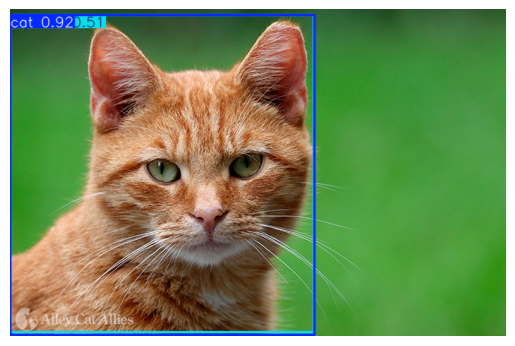

In [17]:
# 시각화
img = result[0].plot()

img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
plt.imshow(img_rgb)
plt.axis('off')
plt.show()

In [ ]:
# YOLO, 탐지+분류, 이미지 데이터셋, 모델 학습(라벨링, data.yaml)

In [18]:
from IPython.display import Image

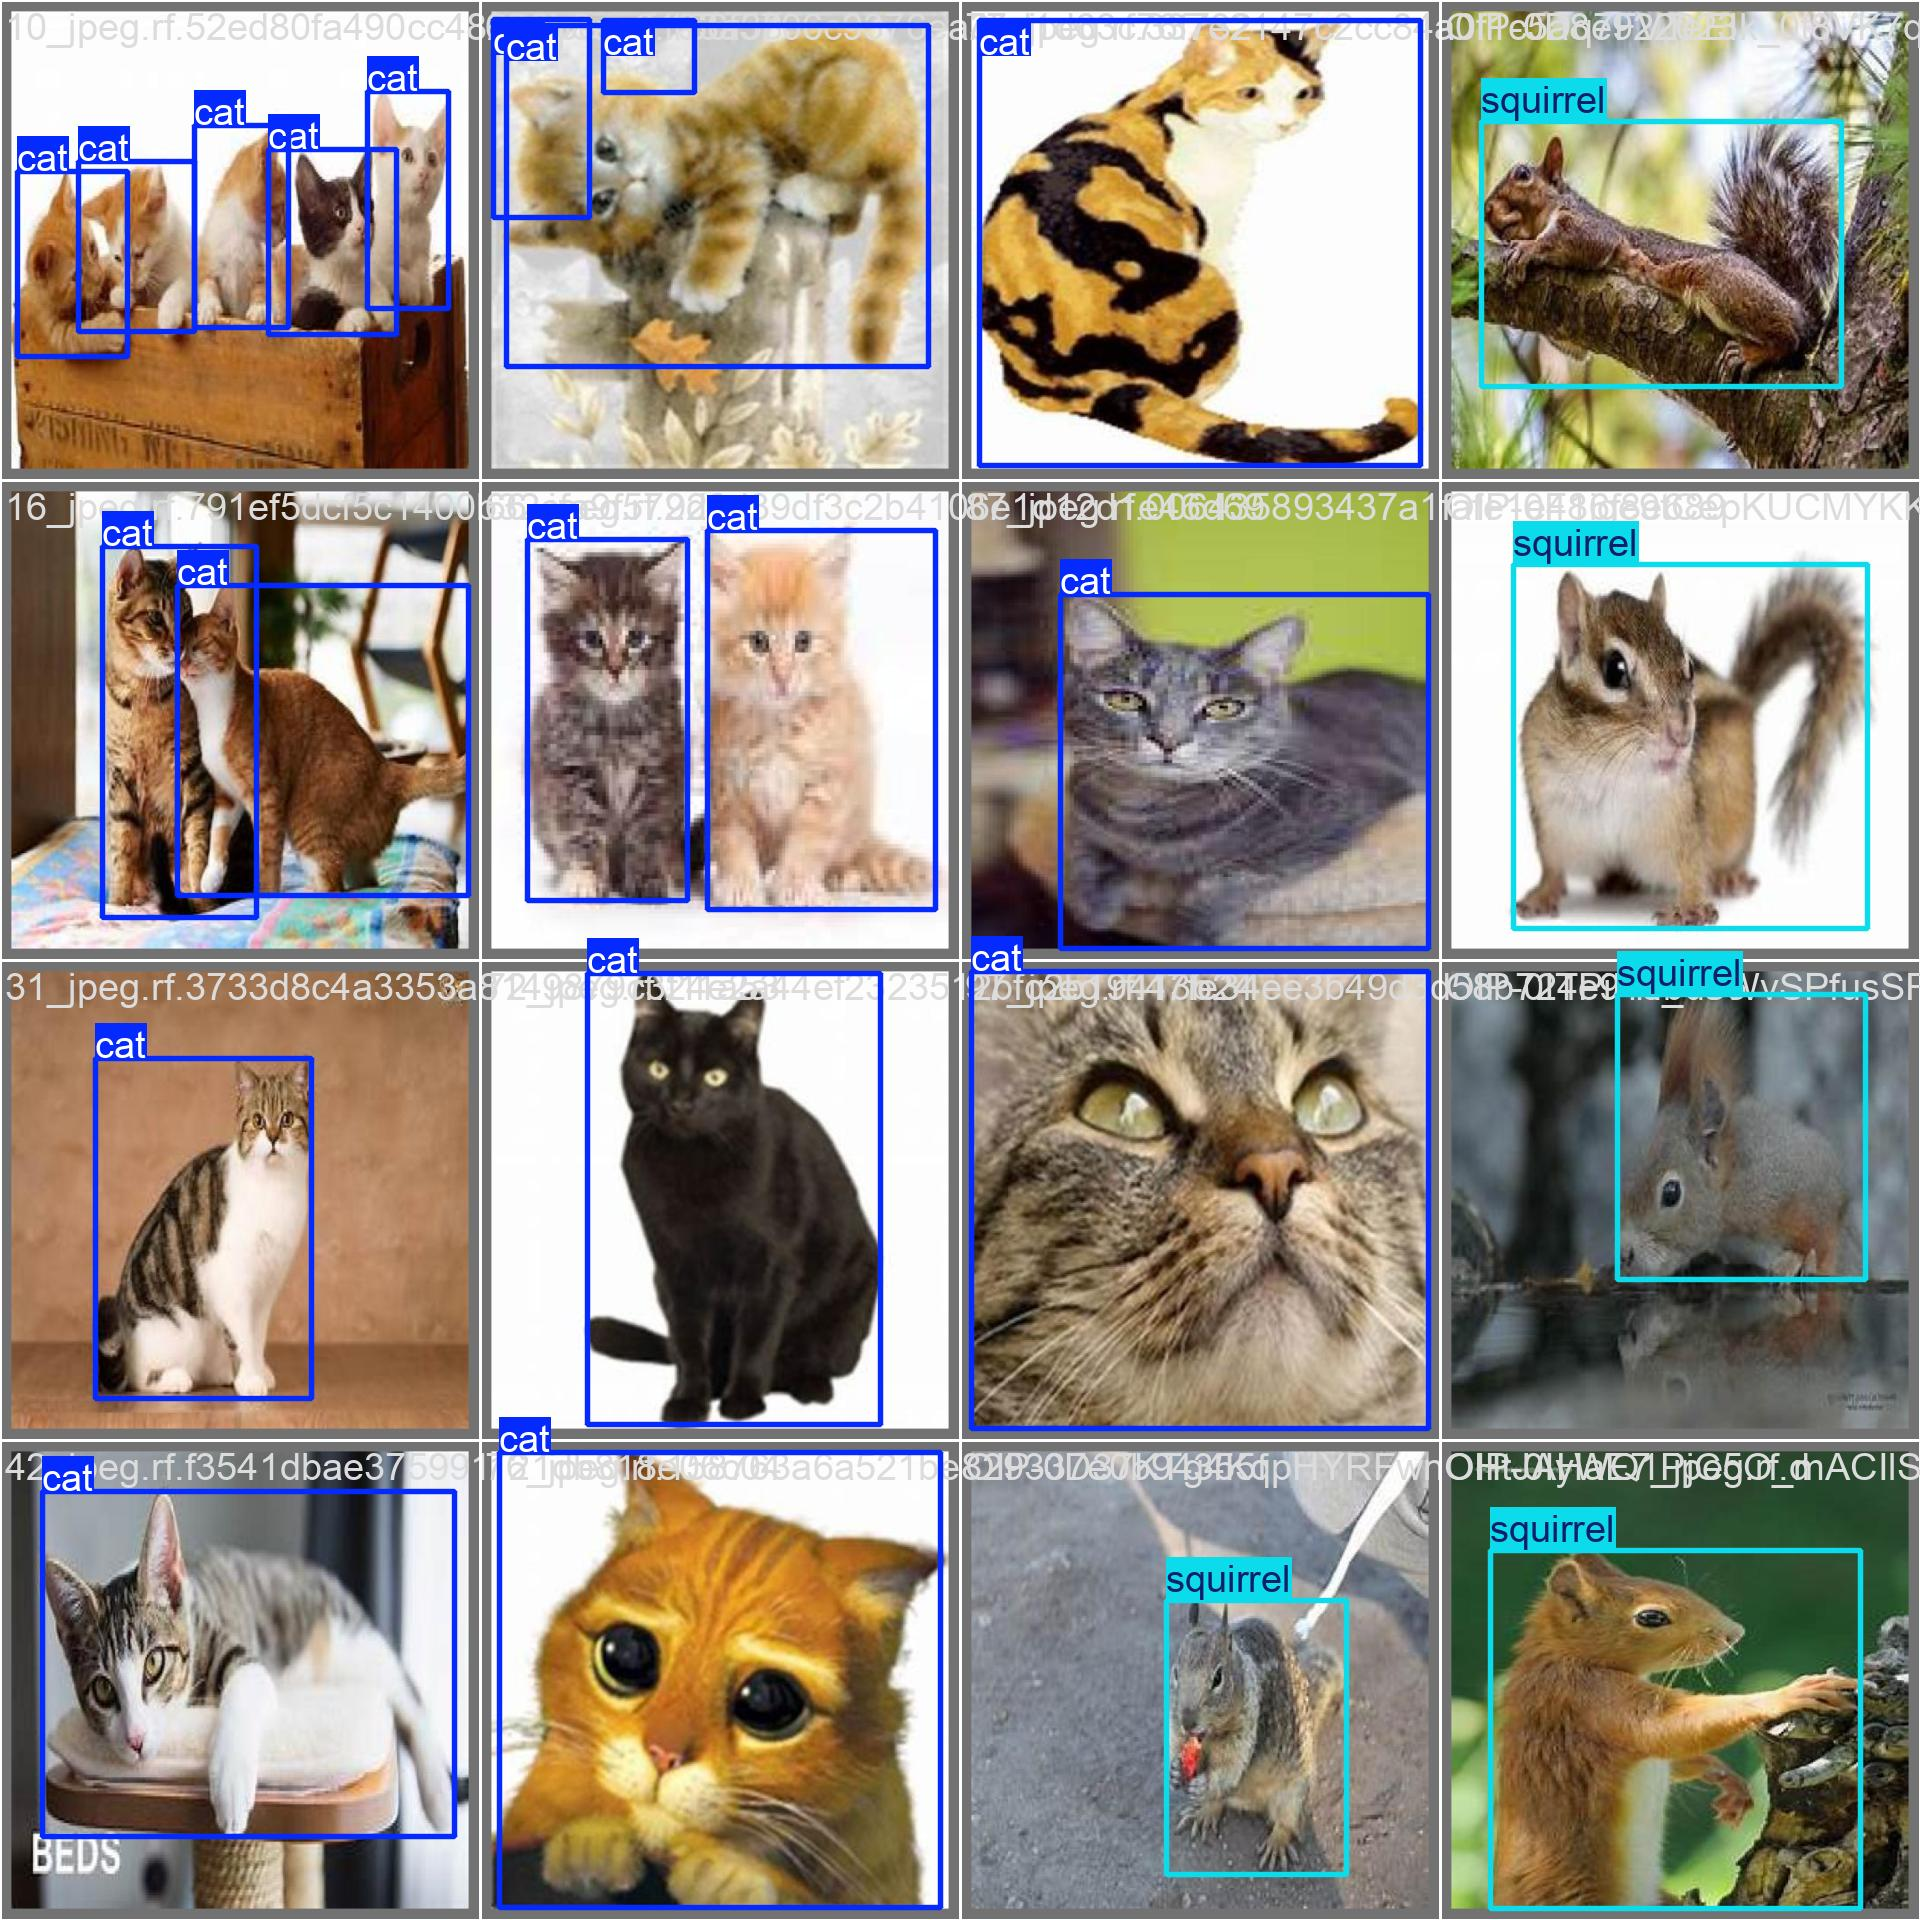

In [23]:
# 검증 배치 이미지와 모델이 예측한 결과값 비교
Image(filename='./runs/detect/train/val_batch0_labels.jpg', width=800)

### 정리
1. YOLO : 실시간 객체탐지 특화된 모델
2. 탐지(Localization) + 분류(Recognition)를 한 번에 처리한다.(one - stage)
3. 라벨링(답지데이터)을 실시해야 한다.
4. Data.yaml : 학습할 모델이 어떤 이미지, 어떤 모델, 어떤 클래스를 가지고 학습 할 건지에 대한 정보가 담겨있는 파일
5. mAP : 종합 성능 지표